# Figure 4: ANN performance

How well the ANN (`models/ann_model.keras`) predicts body heading on trajectories it has not seen, and where it fails.

**Requires** `02_training_and_testing_the_ann.ipynb` to have been run: it reads the training-ready data (`04_trainingdata/`), the saved model and the five-seed ensemble agreement (`tables/ann_ensemble_agreement.csv`). The train/test split is the one of notebook 02 (trajectory-grouped, seed 42, 33 % test).

**Output**: `publication_figures/figure_4.svg`, a [figurefirst](https://github.com/FlyRanch/figurefirst) layout on a letter page, built like `publication_figures/figure_1.svg`. Its template layer ("Layer 1", hidden in the output) holds one rectangle per panel; each rectangle is a figurefirst axis, and the rectangles are grouped into three figurefirst figures:

- `trajecs` (axes `trajec_1` … `trajec_6`): a 2 × 3 grid of example held-out trajectories.
- `heatmaps` (axes `heatmap_test`, `heatmap_rotated`, `heatmap_colorbar`): predicted vs. true heading on the held-out frames.
- `errors` (axes `error_training`, `error_slip`, `error_agreement`, `confidence_colorbar`): the error analysis of `figures/ann_performance_errors` (notebook 02), panel C next to the heatmaps and panels A and B below.

The notebook creates the layout if it does not exist and redraws the panels into the `trajecs`, `heatmaps` and `errors` layers on every run. Changes made in Inkscape to the rectangles (moving or resizing them) or to other layers are kept.

**Graphics**:
- **Example trajectories.** Each rectangle holds two copies of one held-out trajectory, laid out like Figure 1's "Before" and "After" but without panel labels (they are added in Inkscape), under a header with the wind speed and ANN error: first the ground-truth (Viterbi-corrected) heading, in black (`bone`, from light grey, as in Figure 1's "After"), then the ANN heading, in purple. Both are drawn with the glyphs of Figure 1, smaller but as dense along the path: the trajectory (grey line) and, at points spaced evenly along the path, the air velocity (blue) and thrust (brown) arrows and the heading wedge, light at the start of the trajectory to dark at the end. The two copies are stacked or side by side, whichever draws the trajectory larger, at one scale per rectangle with a scale bar. The wind blows toward +x (left to right).
- **Heatmaps.** True vs. predicted heading of every held-out frame (0–360°, so upwind flight, at 180°, sits in the middle), as in `generate_figure_for_paper.ipynb` on the `Christina` branch: once for the held-out trajectories as recorded, and once with each trajectory rotated to a random wind direction (`augment_trajectories(..., wind_augment=True)`, the rotation used to augment the training set).
- **Error analysis.** One dot per trajectory, coloured by its mean heading confidence (the Viterbi forward-backward posterior, `heading_confidence`), with low-confidence trajectories drawn on top. Confidence is crowded near 1, so the colour scale is logarithmic in 1 − confidence, from 0.5 to 0.99999 (higher values are drawn as 0.99999; that is 38 % of trajectories). Error is the median per-trajectory angular error (deg).

## Setup

In [1]:
import os
import sys
import warnings

# TensorFlow must load before pandas (see CLAUDE.md, "TensorFlow deadlock"); the model is also called directly below
import keras
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from IPython.display import SVG, display
from scipy.stats import spearmanr
from sklearn.model_selection import GroupShuffleSplit

with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # figurefirst emits SyntaxWarnings on import under Python 3.12
    import figurefirst as fifi

sys.path.insert(0, os.path.abspath('../utils'))
import fly_plot_lib_plot as fpl
from utils import (FLY_DRAG_COEFF, augment_trajectories, circular_distance, pull_out_individual_trajectories,
                   register_geodesic_loss)

plt.rcParams['svg.fonttype'] = 'none'   # keep text editable in Inkscape
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']

LAYOUT_PATH = '../publication_figures/figure_4.svg'

/Users/florisvb/src/drosophila_body_orientation_predictor/.venv/lib/python3.12/site-packages/pynumdiff/__init__.py:9: UserWarning: tvrdiff, robustdiff, and lineardiff not available due to lack of convex solver. To use those, install CVXPY.
  warn("tvrdiff, robustdiff, and lineardiff not available due to lack of convex solver. To use those, install CVXPY.")


## Layout

Letter page in Inkscape's default user units (96 px/in), with the panels spanning `FIG_W` = 6.5 in, centred on the page. From the top: the 2 × 3 grid of example trajectories; the two heatmaps, their colour bar and error panel C; error panels A and B and the confidence colour bar. Each rectangle is the plotting area of its axes: tick labels and axis labels go outside it, in the gaps left for them (`YLABEL_IN`, `XLABEL_IN`). Set `OVERWRITE_LAYOUT = True` to regenerate the layout from these constants. This discards any edits made to the file in Inkscape.

In [2]:
OVERWRITE_LAYOUT = False

PX_PER_IN = 96
PAGE_W, PAGE_H = 8.5, 11.0         # in
FIG_W = 6.5                        # in, width spanned by the panels
LEFT, TOP = (PAGE_W - FIG_W) / 2, 1.0
RIGHT = LEFT + FIG_W
YLABEL_IN = 0.45                   # room left of a panel for its tick labels and y-axis label (in)
XLABEL_IN = 0.6                    # room below a row for its tick labels and x-axis label (in)
CBAR_W = 0.08                      # colour bar width (in)
CBAR_LABEL_IN = 0.4                # room right of a colour bar for its tick labels and label (in)

# Example trajectories: 2 x 3 grid
TRAJ_ROWS, TRAJ_COLS = 2, 3
TRAJ_GAP = 0.2
TRAJ_W = (FIG_W - (TRAJ_COLS - 1) * TRAJ_GAP) / TRAJ_COLS
TRAJ_H = 1.7
# Heatmaps (square, the second without y tick labels), their colour bar, and error panel C
HEAT_TOP = TOP + TRAJ_ROWS * TRAJ_H + (TRAJ_ROWS - 1) * TRAJ_GAP + 0.45
HEAT = 1.55
HEAT_GAP = 0.15
# Error panels A and B and the confidence colour bar
ERR_TOP = HEAT_TOP + HEAT + XLABEL_IN
ERR_H = 1.4
ERR_GAP = 0.3


def panel_rects():
    '''{figure name: [(axis name, x, y, w, h), ...]} in inches from the page's top left corner'''
    trajecs = [(f'trajec_{r * TRAJ_COLS + c + 1}', LEFT + c * (TRAJ_W + TRAJ_GAP), TOP + r * (TRAJ_H + TRAJ_GAP),
                TRAJ_W, TRAJ_H) for r in range(TRAJ_ROWS) for c in range(TRAJ_COLS)]
    x_test = LEFT + YLABEL_IN
    x_rot = x_test + HEAT + HEAT_GAP
    x_hbar = x_rot + HEAT + 0.08
    x_c = x_hbar + CBAR_W + CBAR_LABEL_IN + YLABEL_IN
    heatmaps = [('heatmap_test', x_test, HEAT_TOP, HEAT, HEAT),
                ('heatmap_rotated', x_rot, HEAT_TOP, HEAT, HEAT),
                ('heatmap_colorbar', x_hbar, HEAT_TOP, CBAR_W, HEAT)]
    err_w = (FIG_W - YLABEL_IN - ERR_GAP - 0.1 - CBAR_W - CBAR_LABEL_IN) / 2
    x_a = LEFT + YLABEL_IN
    x_b = x_a + err_w + ERR_GAP
    errors = [('error_training', x_c, HEAT_TOP, RIGHT - x_c, HEAT),
              ('error_slip', x_a, ERR_TOP, err_w, ERR_H),
              ('error_agreement', x_b, ERR_TOP, err_w, ERR_H),
              ('confidence_colorbar', x_b + err_w + 0.1, ERR_TOP, CBAR_W, ERR_H)]
    return {'trajecs': trajecs, 'heatmaps': heatmaps, 'errors': errors}


def group_svg(figure, rects):
    '''A figurefirst figure: a group of rectangles, each a figurefirst axis'''
    out = [f'    <g id="{figure}_template">', f'      <figurefirst:figure figurefirst:name="{figure}" />']
    for name, x, y, w, h in rects:
        out.append(f'      <rect id="{name}" x="{x * PX_PER_IN:g}" y="{y * PX_PER_IN:g}" width="{w * PX_PER_IN:g}" '
                   f'height="{h * PX_PER_IN:g}" style="fill:none;stroke:#000000;stroke-width:1">\n'
                   f'        <figurefirst:axis figurefirst:name="{name}" />\n'
                   f'      </rect>')
    return '\n'.join(out) + '\n    </g>\n'


def make_layout_svg(path):
    groups = ''.join(group_svg(figure, rects) for figure, rects in panel_rects().items())
    svg = f'''<?xml version="1.0" encoding="UTF-8" standalone="no"?>
<svg
   xmlns="http://www.w3.org/2000/svg"
   xmlns:svg="http://www.w3.org/2000/svg"
   xmlns:inkscape="http://www.inkscape.org/namespaces/inkscape"
   xmlns:sodipodi="http://sodipodi.sourceforge.net/DTD/sodipodi-0.dtd"
   xmlns:figurefirst="http://flyranch.github.io/figurefirst/"
   width="{PAGE_W}in"
   height="{PAGE_H}in"
   viewBox="0 0 {PAGE_W * PX_PER_IN:g} {PAGE_H * PX_PER_IN:g}"
   version="1.1"
   id="svg1">
  <sodipodi:namedview id="namedview1" inkscape:document-units="in" />
  <g inkscape:groupmode="layer" inkscape:label="Layer 1" id="layer1">
{groups}  </g>
</svg>
'''
    with open(path, 'w') as f:
        f.write(svg)


os.makedirs(os.path.dirname(LAYOUT_PATH), exist_ok=True)
if OVERWRITE_LAYOUT or not os.path.exists(LAYOUT_PATH):
    make_layout_svg(LAYOUT_PATH)
    print(f'Wrote layout {LAYOUT_PATH}')
else:
    print(f'Using existing layout {LAYOUT_PATH}')

Using existing layout ../publication_figures/figure_4.svg


## Data and predictions

The split, the trajectories (at least 12 frames) and the per-trajectory error are those of notebook 02. A trajectory's confidence is the mean `heading_confidence` of its frames.

In [3]:
RANDOM_SEED = 42
INPUTS = ['groundspeed', 'groundspeed_angle', 'airspeed', 'airspeed_angle']
KEEP = ['heading_angle_x', 'heading_angle_y', 'trajec_objid']

data = pd.read_csv('../trainingdata/04_trainingdata/all_wind_heading_and_trajectories_augmented_corrected_filtered_headx_heady.csv')
traj_ids = data['trajec_objid'].unique()
gss = GroupShuffleSplit(n_splits=1, test_size=0.33, random_state=RANDOM_SEED)
train_idx, test_idx = next(gss.split(np.zeros((len(traj_ids), 1)), groups=traj_ids))
train_ids, test_ids = set(traj_ids[train_idx]), set(traj_ids[test_idx])

trajs = pull_out_individual_trajectories(data, min_traj_length=12)
train_trajs = [t.reset_index(drop=True) for t in trajs if t['trajec_objid'].iloc[0] in train_ids]
test_trajs = [t.reset_index(drop=True) for t in trajs if t['trajec_objid'].iloc[0] in test_ids]
test_by_id = {t['trajec_objid'].iloc[0]: t for t in test_trajs}
print(len(train_trajs), 'train trajectories,', len(test_trajs), 'held-out trajectories')

register_geodesic_loss()
ann = keras.models.load_model('../models/ann_model.keras')


def ann_predict(emb):
    '''Predicted and true heading (rad) of every row of an augment_trajectories table'''
    p = ann(emb[INPUTS].values.astype('float32'), training=False).numpy()   # ann.predict can deadlock
    return np.arctan2(p[:, 1], p[:, 0]), np.arctan2(emb['heading_angle_y'].values, emb['heading_angle_x'].values)


def per_trajectory_error(emb):
    '''Median angular error per trajectory (deg)'''
    pred, true = ann_predict(emb)
    err = np.degrees(circular_distance(true, pred))
    return pd.DataFrame({'trajec_objid': emb['trajec_objid'].values, 'err': err}).groupby('trajec_objid')['err'].median()


test_default = augment_trajectories(test_trajs, input_names=INPUTS, output_names=KEEP)
test_rotated = augment_trajectories(test_trajs, input_names=INPUTS, output_names=KEEP, wind_augment=True, wrap_angles=True)
err_train = per_trajectory_error(augment_trajectories(train_trajs, input_names=INPUTS, output_names=KEEP))
err_test = per_trajectory_error(test_default)
err_rotated = per_trajectory_error(test_rotated)

confidence = data.groupby('trajec_objid')['heading_confidence'].mean()
slip = pd.Series({t['trajec_objid'].iloc[0]: np.degrees(np.abs(circular_distance(t['heading_angle'].values,
                                                                                   t['airspeed_angle'].values))).mean()
                  for t in trajs})
agreement = pd.read_csv('../tables/ann_ensemble_agreement.csv').set_index('trajec_objid')['R']
print(f'median per-trajectory error  train: {err_train.median():.2f}°   held-out: {err_test.median():.2f}°   '
      f'held-out, rotated: {err_rotated.median():.2f}°')

Detected 3321 trajectories.
3321 trajectories with more than 12 timesteps.


2225 train trajectories, 1096 held-out trajectories


median per-trajectory error  train: 5.04°   held-out: 4.96°   held-out, rotated: 6.24°


## Example trajectories

Candidate rows 4, 8, 9, 15, 18 and 19 of `05_ann_performance_examples.ipynb`, frozen as trajectory ids (candidate row numbers change whenever the data or the split does): two per wind speed.

In [4]:
TRAJEC_IDS = [
    '20130401_180544_10224',   # row 4, 0.3 m/s
    '20130321_182151_5320',    # row 8, 0.4 m/s
    '20121210_201202_776',     # row 9, 0.4 m/s
    '20130418_190232_2658',    # row 15, 0.6 m/s
    '20130404_181148_1141',    # row 18, 0.6 m/s
    '20130410_185709_8978',    # row 19, 0.6 m/s
]
missing = [t for t in TRAJEC_IDS if t not in test_by_id]
assert not missing, f'not held out: {missing}'
pd.DataFrame({'windspeed': [test_by_id[t]['windspeed'].iloc[0] for t in TRAJEC_IDS],
              'n_frames': [len(test_by_id[t]) for t in TRAJEC_IDS],
              'ann_err': err_test.loc[TRAJEC_IDS].values,
              'confidence': confidence.loc[TRAJEC_IDS].values}, index=TRAJEC_IDS).round(3)

,windspeed,n_frames,ann_err,confidence
20130401_180544_10224,0.3,81,4.914,1.000
20130321_182151_5320,0.4,146,4.770,0.997
20121210_201202_776,0.4,77,5.111,0.978
20130418_190232_2658,0.6,77,21.224,0.985
20130404_181148_1141,0.6,72,12.382,0.963
20130410_185709_8978,0.6,29,16.021,0.999


## Plotting

Glyph colours and the scale bar follow `generate_figure_1.ipynb`; the glyphs are smaller, and as dense along the path as in Figure 1 (about 0.18 in apart on paper). Sizes are given on paper (inches) and converted with the panel's scale (inches per metre).

In [5]:
FONTSIZE = 7
GLYPH_SPACING_IN = 0.18    # distance between glyphs along the path, on paper (in); Figure 1's median spacing
WEDGE_IN = 0.1             # heading wedge radius (in); its tip is 0.75 radius ahead of the body centre
WEDGE_ANGLE = 28           # heading wedge opening angle (deg)
ARROW_IN = 0.18            # arrow length for a 0.5 m/s air velocity, or for the thrust balancing its drag (in)
ARROW_WIDTH_IN = 0.007     # arrow shaft width (in)
PAD_IN = 0.1               # margin around the trajectory, for the glyphs at its ends (in)
LABEL_IN = 0.13            # space at the top of each rectangle for its header (in)

# Heading wedges run from light (start of the trajectory) to dark (end): ground truth in black (bone cut at its
# white end, as Figure 1's Viterbi-corrected heading), the ANN in purple
ANN_COLORS = ('#b9a3dc', '#3f1a73')
ANN_CMAP = mcolors.LinearSegmentedColormap.from_list('ann', ANN_COLORS)
TRUTH_CMAP = mcolors.ListedColormap(plt.get_cmap('bone_r')(np.linspace(0.25, 1, 256)), name='bone_r_cut')
TRACK_COLOR = '0.45'
AIR_COLOR = '#2b5cd6'
THRUST_COLOR = '#8c510a'   # brown, as in Figure 1

# Heading confidence: plasma without its yellow end, from blue (high) to orange (low), on a log scale in 1 - confidence
# (it is crowded near 1); a trajectory whose mean confidence is above 1 - 1e-5 is drawn as 1 - 1e-5
CONF_CMAP = mcolors.ListedColormap(plt.get_cmap('plasma')(np.linspace(0, 0.8, 256)), name='plasma_cut')
CONF_NORM = mcolors.LogNorm(1e-5, 0.5, clip=True)
CONF_TICKS = [0.5, 0.9, 0.99, 0.999, 0.9999, 0.99999]
# Heatmap colours, from generate_figure_for_paper.ipynb (Christina branch)
HEAT_CMAP = mcolors.LinearSegmentedColormap.from_list(
    'heat', list(zip(np.r_[0, np.linspace(0.01, 1, 6)],
                     ['white', 'navy', 'cornflowerblue', 'aqua', 'yellow', 'red', 'darkred'])))


def style_axes(ax, title=None):
    if title:
        ax.set_title(title, fontsize=FONTSIZE, pad=4)
    ax.tick_params(labelsize=FONTSIZE - 1, length=2, width=0.5)
    ax.tick_params(which='minor', length=1, width=0.4)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_linewidth(0.5)

In [6]:
def glyph_frames(x, y, n):
    '''Indices of n frames spaced evenly along the path (not in time)'''
    s = np.r_[0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]
    return np.unique(np.minimum(np.searchsorted(s, np.linspace(0, s[-1], n)), len(x) - 1))


def wedges(ax, x, y, h, scale, facecolors, zorder):
    fpl.colorline_with_heading(ax, x, y, np.zeros(len(x)), h, size_radius=WEDGE_IN / scale, size_angle=WEDGE_ANGLE,
                               deg=False, colornorm=[0, 1], show_centers=False, edgecolor='none', alpha=1)
    w = ax.collections[-1]
    w.set_array(None)                                  # colour each wedge directly instead of by colormap
    w.set_facecolor(facecolors)
    w.set_zorder(zorder)


def plot_heading(ax, df, heading, scale, cmap):
    '''Trajectory with air velocity, thrust and heading glyphs, at scale in/m; the heading wedges are coloured by
    time along cmap'''
    x, y = df['position_x'].values, df['position_y'].values
    n = max(6, int(round(np.hypot(np.diff(x), np.diff(y)).sum() * scale / GLYPH_SPACING_IN)) + 1)
    i = glyph_frames(x, y, n)
    g = df.iloc[i]
    gx, gy = g['position_x'].values, g['position_y'].values

    ax.plot(x, y, color=TRACK_COLOR, lw=0.6, zorder=1)
    arrows = dict(angles='xy', scale_units='xy', scale=1, units='inches', width=ARROW_WIDTH_IN,
                  headwidth=3.5, headlength=4, headaxislength=3.5, zorder=3)
    air_k = ARROW_IN / scale / 0.5
    ax.quiver(gx, gy, g['airvelocity_x'] * air_k, g['airvelocity_y'] * air_k, color=AIR_COLOR, **arrows)
    thrust_k = ARROW_IN / scale / (0.5 * FLY_DRAG_COEFF)   # thrust balancing the drag at 0.5 m/s: 5.5 µN
    ax.quiver(gx, gy, np.cos(g['thrust_angle']) * g['thrust'] * thrust_k,
              np.sin(g['thrust_angle']) * g['thrust'] * thrust_k, color=THRUST_COLOR, **arrows)
    t = (g['timestamp'].values - df['timestamp'].min()) / np.ptp(df['timestamp'].values)
    wedges(ax, gx, gy, heading[i], scale, cmap(t), 4)


CORNERS = [(0.1, 0.06), (0.9, 0.06), (0.9, 0.94)]  # axes fraction; not top left, under the panel label


def emptiest_corner(ax, x, y):
    '''The axes corner farthest from the trajectory'''
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    fx, fy = (x - x0) / (x1 - x0), (y - y0) / (y1 - y0)
    return max(CORNERS, key=lambda c: np.min(np.hypot(fx - c[0], fy - c[1])))


def draw_scale_bar(ax, extent, anchor):
    '''Compact scale bar near anchor (axes fraction): the largest 1/2/5 x 10^n that is at most 30 % of extent (m)'''
    max_bar = 0.3 * extent
    magnitude = 10 ** np.floor(np.log10(max_bar))
    bar = max(s * magnitude for s in (1, 2, 5) if s * magnitude <= max_bar)
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    w, h = x1 - x0, y1 - y0
    cx = np.clip(x0 + anchor[0] * w, x0 + bar / 2, x1 - bar / 2)
    cy = y0 + anchor[1] * h
    ax.plot([cx - bar / 2, cx + bar / 2], [cy, cy], color='k', lw=0.75, solid_capstyle='butt')
    label_below = anchor[1] > 0.5
    ax.text(cx, cy + (-0.02 if label_below else 0.02) * h, f'{bar * 100:g} cm', ha='center',
            va='top' if label_below else 'bottom', fontsize=FONTSIZE - 1)


def arrange(W, H, w, h):
    '''Fit two copies of a w x h (m) trajectory into a W x H (in) rectangle, stacked or side by side, whichever draws
    it larger, as in Figure 1 but with no room for panel labels. Returns the panel size (in), the panel origins (in)
    and the scale (in/m).'''
    arrangements = [
        ((W, H / 2), [(0, H / 2), (0, 0)]),       # stacked
        ((W / 2, H), [(0, 0), (W / 2, 0)]),       # side by side
    ]
    def fit(box):
        return min((box[0] - 2 * PAD_IN) / w, (box[1] - 2 * PAD_IN) / h)
    box, origins = max(arrangements, key=lambda a: fit(a[0]))
    return box, origins, fit(box)


def plot_example(ax, df):
    '''One held-out trajectory into the rectangle ax: its ground-truth and its ANN heading, two panels at the same
    scale, stacked or side by side, whichever draws the trajectory larger, under a header with the wind speed and the
    ANN error'''
    fw, fh = ax.figure.get_size_inches()
    pos = ax.get_position()
    W, H = pos.width * fw, pos.height * fh   # in
    ax.axis('off')

    x, y = df['position_x'].values, df['position_y'].values
    w, h = np.ptp(x), np.ptp(y)
    (bw, bh), origins, scale = arrange(W, H - LABEL_IN, w, h)
    pred, _ = ann_predict(augment_trajectories([df], input_names=INPUTS, output_names=KEEP))
    panels = [(df['heading_angle'].values, TRUTH_CMAP), (pred, ANN_CMAP)]   # ground truth first, then the ANN
    tid = df['trajec_objid'].iloc[0]
    ax.text(0, 1, f'{df["windspeed"].iloc[0]:.1f} m/s wind, ANN error {err_test[tid]:.1f}°',
            transform=ax.transAxes, ha='left', va='top', fontsize=FONTSIZE)

    cx, cy = (x.min() + x.max()) / 2, (y.min() + y.max()) / 2
    for (bx, by), (heading, cmap) in zip(origins, panels):
        inset = ax.inset_axes([bx / W, by / H, bw / W, bh / H])
        plot_heading(inset, df, heading, scale, cmap)
        inset.set_xlim(cx - bw / scale / 2, cx + bw / scale / 2)
        inset.set_ylim(cy - bh / scale / 2, cy + bh / scale / 2)
        inset.set_aspect('equal')
        inset.axis('off')
        for artist in inset.get_children():
            artist.set_clip_on(False)                    # let long arrows run past the panel edge
    draw_scale_bar(inset, max(w, h), emptiest_corner(inset, x, y))

In [7]:
HEAT_BIN = 4   # deg


def heading_histogram(emb):
    pred, true = ann_predict(emb)
    bins = np.arange(0, 360 + HEAT_BIN, HEAT_BIN)
    counts, _, _ = np.histogram2d(np.degrees(true) % 360, np.degrees(pred) % 360, bins=[bins, bins])
    return bins, counts


def plot_heatmaps(ax_test, ax_rot, cax):
    '''True vs. predicted heading of every held-out frame, as recorded and rotated to random wind directions'''
    hists = [heading_histogram(test_default), heading_histogram(test_rotated)]
    norm = mcolors.LogNorm(1, max(c.max() for _, c in hists))
    panels = [(ax_test, 'Held-out trajectories', err_test), (ax_rot, 'Held-out, random wind direction', err_rotated)]
    for (ax, title, err), (bins, counts) in zip(panels, hists):
        mesh = ax.pcolormesh(bins, bins, np.ma.masked_equal(counts, 0).T, cmap=HEAT_CMAP, norm=norm, rasterized=True)
        ax.set_xlim(0, 360); ax.set_ylim(0, 360)
        ax.set_aspect('equal')
        ax.set_xticks(range(0, 361, 90)); ax.set_yticks(range(0, 361, 90))
        ax.set_xlabel('True heading (°)', fontsize=FONTSIZE)
        style_axes(ax, f'{title}\nmedian error {err.median():.1f}°')
    ax_test.set_ylabel('Predicted heading (°)', fontsize=FONTSIZE)
    ax_rot.tick_params(labelleft=False)
    cb = ax_test.figure.colorbar(mesh, cax=cax)
    cb.set_label(f'Frames per {HEAT_BIN}° × {HEAT_BIN}° bin', fontsize=FONTSIZE)
    cb.ax.tick_params(labelsize=FONTSIZE - 1, length=2, width=0.5)
    cb.outline.set_linewidth(0.5)

In [8]:
DOT = dict(s=4, lw=0, alpha=0.7, cmap=CONF_CMAP, norm=CONF_NORM, rasterized=True)


def confidence_scatter(ax, x, y, tids):
    '''One dot per trajectory, coloured by its confidence, low-confidence trajectories on top'''
    c = 1 - confidence.loc[tids].values
    order = np.argsort(c)
    return ax.scatter(np.asarray(x)[order], np.asarray(y)[order], c=c[order], **DOT)


def binned_median(ax, x, y, n=10):
    b = pd.qcut(x, n, duplicates='drop')
    g = pd.DataFrame({'x': x, 'y': y, 'b': b}).groupby('b', observed=True).agg(x=('x', 'median'), y=('y', 'median'))
    ax.plot(g['x'], g['y'], '-o', color='black', lw=1, ms=2, label='decile median')


def spearman_label(ax, x, y, xpos, ypos):
    rho = spearmanr(x, y).statistic
    ax.text(xpos, ypos, rf'Spearman $\rho = {rho:.2f}$', transform=ax.transAxes, ha='left',
            va='top' if ypos > 0.5 else 'bottom', fontsize=FONTSIZE - 1)


def plot_error_training(ax):
    '''Error inside (training set) vs. outside (held-out) the training set'''
    rng = np.random.default_rng(0)
    for i, e in enumerate([err_train, err_test]):
        confidence_scatter(ax, i + rng.uniform(-0.28, 0.28, len(e)), e.values, e.index)
        ax.hlines(e.median(), i - 0.35, i + 0.35, color='black', lw=1.2, zorder=3)
        ax.text(i, e.median() * 1.3, f'{e.median():.1f}°', ha='center', va='bottom', fontsize=FONTSIZE - 1, zorder=4,
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))
    ax.set_yscale('log'); ax.set_xlim(-0.6, 1.6)
    ax.set_xticks([0, 1], [f'Training\n(n = {len(err_train)})', f'Held-out\n(n = {len(err_test)})'])
    ax.set_ylabel('ANN error (°, per trajectory)', fontsize=FONTSIZE)
    style_axes(ax)


def plot_error_slip(ax):
    '''Error vs. mean |slip angle| (held-out trajectories)'''
    s = slip.loc[err_test.index]
    confidence_scatter(ax, s.values, err_test.values, err_test.index)
    binned_median(ax, s.values, err_test.values)
    ax.set_yscale('log')
    ax.set_xlabel('Mean |slip angle| (°)', fontsize=FONTSIZE)
    ax.set_ylabel('ANN error (°, per trajectory)', fontsize=FONTSIZE)
    spearman_label(ax, s.values, err_test.values, 0.03, 0.97)
    ax.legend(loc='lower right', frameon=False, fontsize=FONTSIZE - 1)
    style_axes(ax)


def plot_error_agreement(ax):
    '''Error vs. the five-seed ensemble's mean resultant length R (held-out trajectories; R is crowded near 1, so
    1 - R on a log axis, agreement to the right)'''
    R = agreement.loc[err_test.index]
    d = (1 - R).clip(lower=1e-6)
    confidence_scatter(ax, d.values, err_test.values, err_test.index)
    binned_median(ax, d.values, err_test.values)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.invert_xaxis()
    ticks = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
    ax.set_xticks(ticks, [f'{1 - tk:g}' for tk in ticks]); ax.minorticks_off()
    ax.set_xlabel('Ensemble agreement $R$ (log scale in $1 - R$)', fontsize=FONTSIZE)
    spearman_label(ax, R.values, err_test.values, 0.03, 0.03)
    style_axes(ax)


def plot_confidence_colorbar(cax):
    cb = cax.figure.colorbar(matplotlib.cm.ScalarMappable(norm=CONF_NORM, cmap=CONF_CMAP), cax=cax)
    cb.set_ticks([1 - tk for tk in CONF_TICKS], labels=[f'{tk:g}' for tk in CONF_TICKS])
    cb.ax.minorticks_off()
    cb.ax.invert_yaxis()                               # confidence increases upward
    cb.set_label('Mean heading confidence\n(log scale in 1 − confidence)', fontsize=FONTSIZE)
    cb.ax.tick_params(labelsize=FONTSIZE - 1, length=2, width=0.5)
    cb.outline.set_linewidth(0.5)

## Draw the figure

The panels are written into the `trajecs`, `heatmaps` and `errors` layers of `publication_figures/figure_4.svg`, which are cleared first.

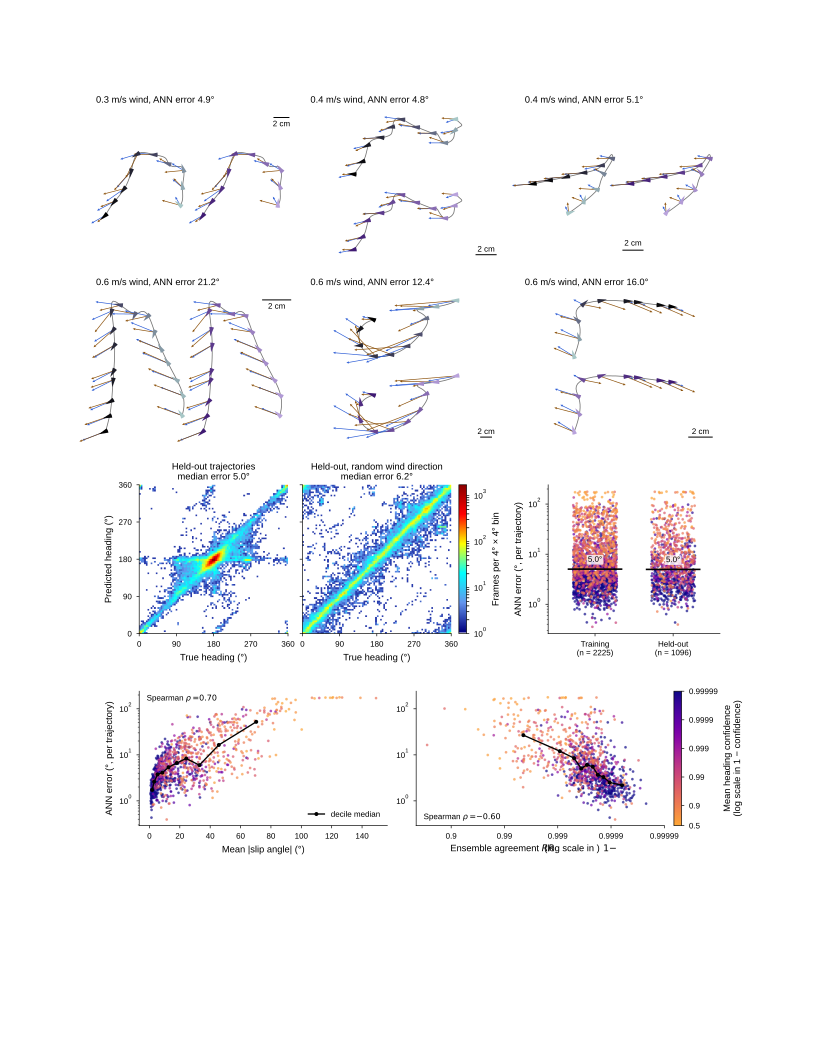

In [9]:
layout = fifi.FigureLayout(LAYOUT_PATH, autogenlayers=True, make_mplfigures=True)
for i, tid in enumerate(TRAJEC_IDS, start=1):
    plot_example(layout.axes[('trajecs', f'trajec_{i}')], test_by_id[tid])
layout.append_figure_to_layer(layout.figures['trajecs'], 'trajecs', cleartarget=True)

plot_heatmaps(*(layout.axes[('heatmaps', name)] for name in ['heatmap_test', 'heatmap_rotated', 'heatmap_colorbar']))
layout.append_figure_to_layer(layout.figures['heatmaps'], 'heatmaps', cleartarget=True)

plot_error_training(layout.axes[('errors', 'error_training')])
plot_error_slip(layout.axes[('errors', 'error_slip')])
plot_error_agreement(layout.axes[('errors', 'error_agreement')])
plot_confidence_colorbar(layout.axes[('errors', 'confidence_colorbar')])
layout.append_figure_to_layer(layout.figures['errors'], 'errors', cleartarget=True)

layout.write_svg(LAYOUT_PATH)
plt.close('all')
display(SVG(LAYOUT_PATH))